# 🧱 MVP-1 — Environment (Maze World)

## 🎯 Goal of MVP-1 (Very Clear)

Create a minimal maze where:
* Greedy behavior fails
* Planning helps
* Imagination is meaningful and visible

_If planning isn’t necessary, the whole project collapses._

## 🧠 Cognitive Requirement (Why This Maze Exists)
Your maze must force the agent to:
- pause at decision junctions
- choose between multiple futures
- avoid dead ends
- benefit from looking ahead

*This mirrors hippocampal decision points in real animals.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Maze Structure

In [2]:
# Legend:
#  0 = free space
#  1 = wall
#  2 = start
#  3 = goal

maze = np.array([
    [2, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 3]
])

HEIGHT, WIDTH = maze.shape


### Maze Environment

In [3]:
class MazeEnv:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        self.start_pos = tuple(np.argwhere(maze == 2)[0])
        self.goal_pos = tuple(np.argwhere(maze == 3)[0])
        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self.agent_pos

    def step(self, action):
        moves = {
            0: (-1, 0),  # up
            1: (1, 0),   # down
            2: (0, -1),  # left
            3: (0, 1)    # right
        }

        dx, dy = moves[action]
        x, y = self.agent_pos
        nx, ny = x + dx, y + dy

        # Check boundaries and walls
        if 0 <= nx < self.height and 0 <= ny < self.width:
            if self.maze[nx, ny] != 1:
                self.agent_pos = (nx, ny)

        reward = 1 if self.agent_pos == self.goal_pos else 0
        done = self.agent_pos == self.goal_pos

        return self.agent_pos, reward, done


In [4]:
def render(env):
    grid = env.maze.copy()

    x, y = env.agent_pos
    grid[x, y] = 4  # agent

    cmap = plt.get_cmap("tab10", 5)

    plt.figure(figsize=(5, 5))
    plt.imshow(grid, cmap=cmap)
    plt.xticks([])
    plt.yticks([])
    plt.title("Maze Environment")
    plt.show()


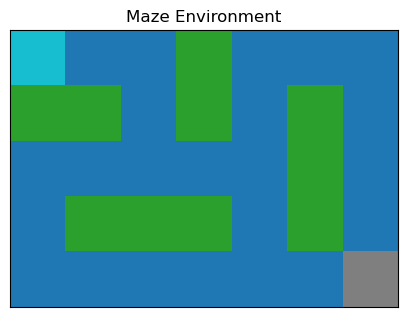

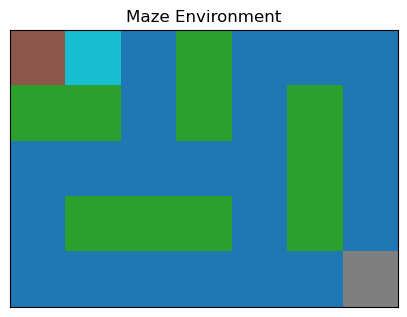

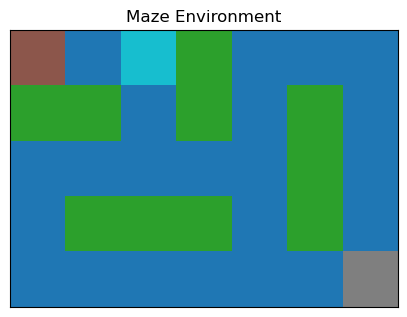

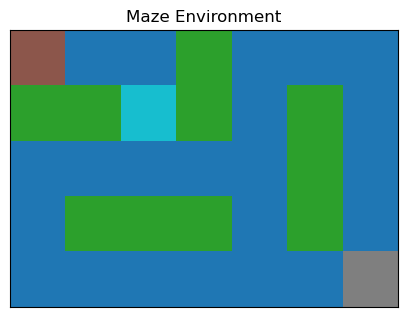

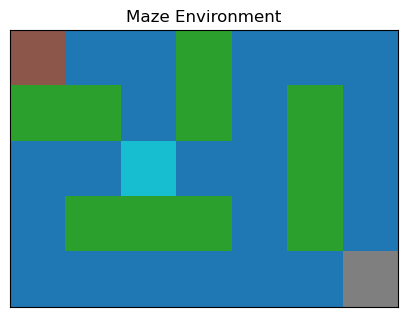

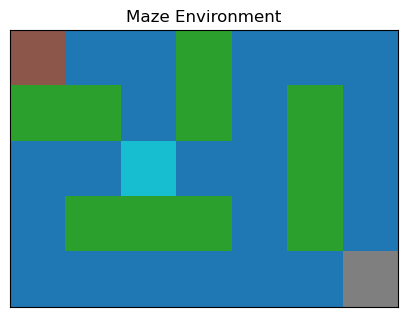

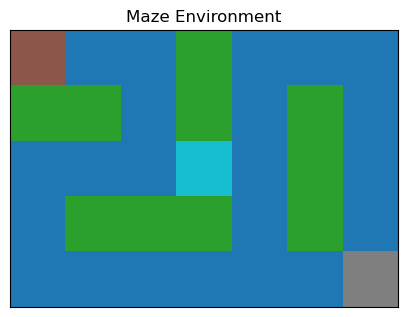

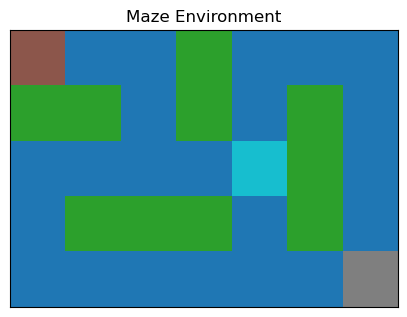

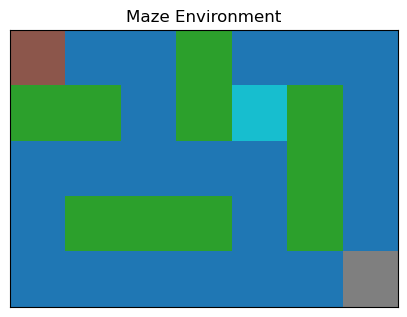

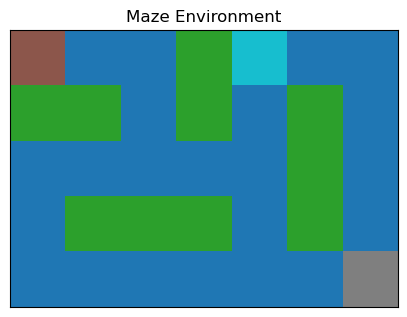

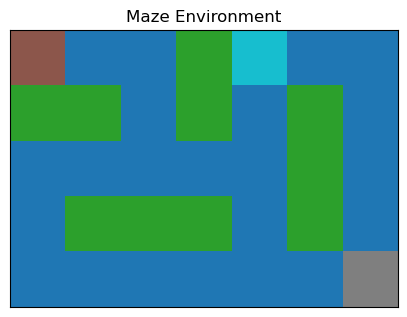

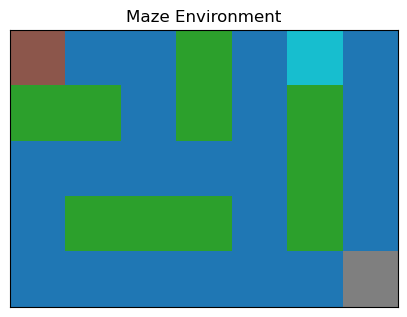

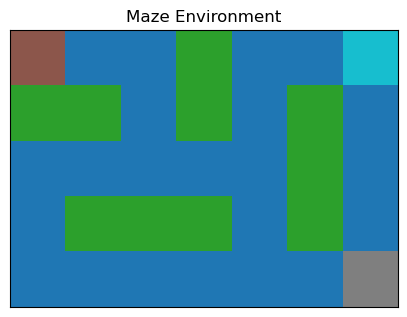

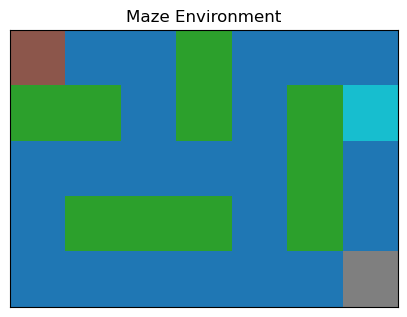

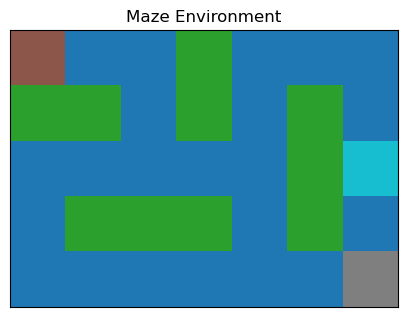

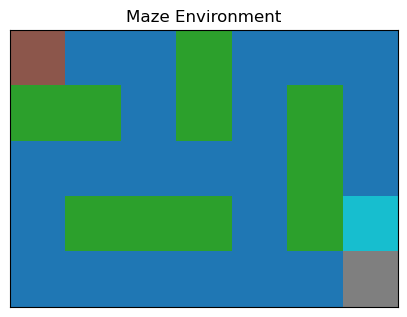

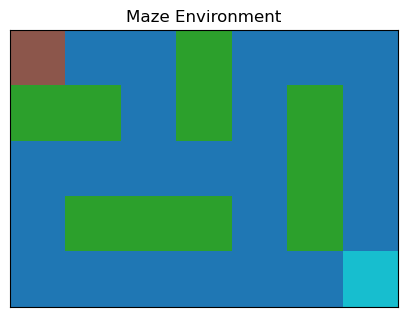

Reached goal!


In [5]:
env = MazeEnv(maze)
render(env)

# Try moving the agent manually
actions = [3, 3, 1, 1, 1, 3, 3, 0, 0, 0, 3, 3, 1, 1, 1, 1]  # right, right, down, down, down...

for a in actions:
    state, reward, done = env.step(a)
    render(env)
    if done:
        print("Reached goal!")
        break


### Random Agent Testing

In [6]:
import random
import time

def run_random_agent(env, max_steps=50, delay=0.3):
    state = env.reset()
    render(env)

    for step in range(max_steps):
        action = random.choice([0, 1, 2, 3])  # up, down, left, right
        next_state, reward, done = env.step(action)

        render(env)
        time.sleep(delay)

        if done:
            print(f"🎯 Reached goal in {step+1} steps (pure luck).")
            return

    print("❌ Did not reach the goal. Random agent failed.")


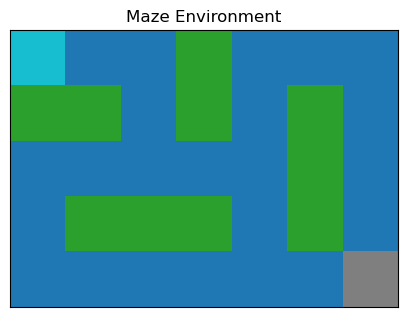

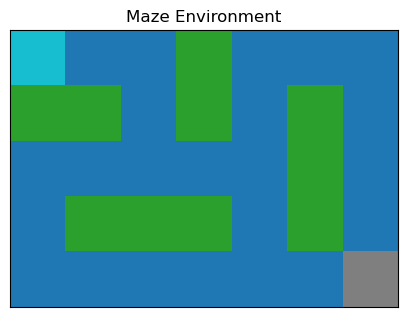

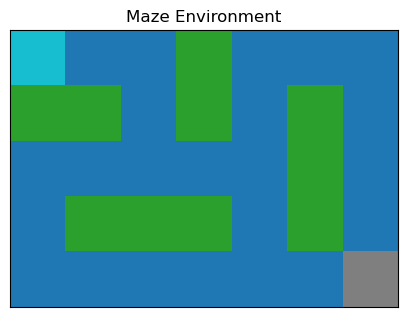

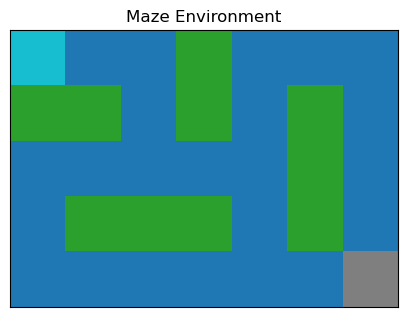

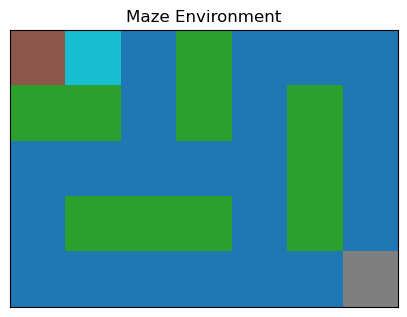

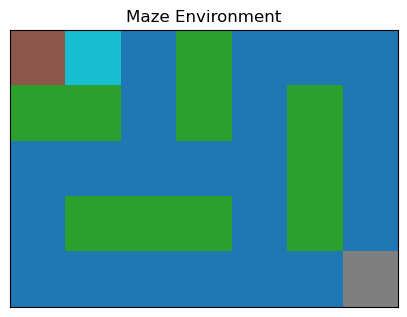

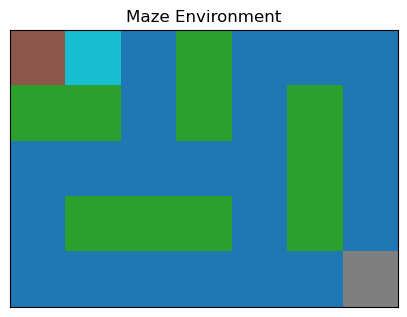

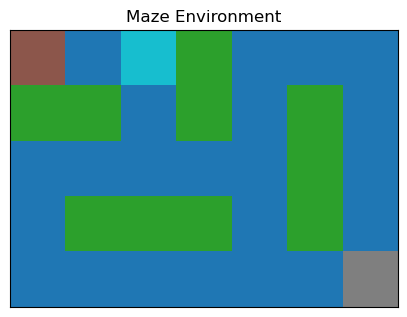

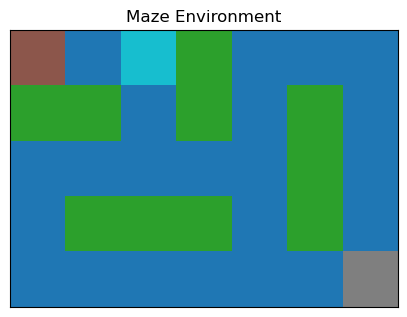

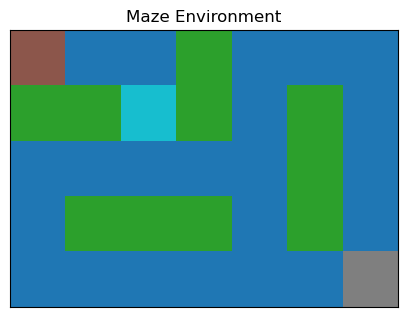

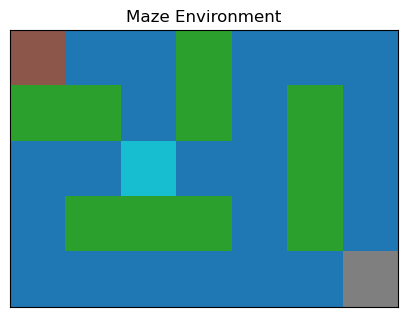

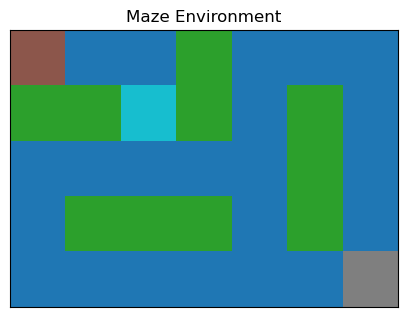

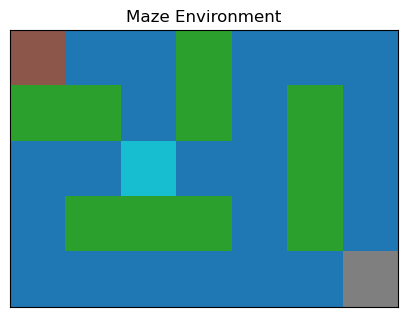

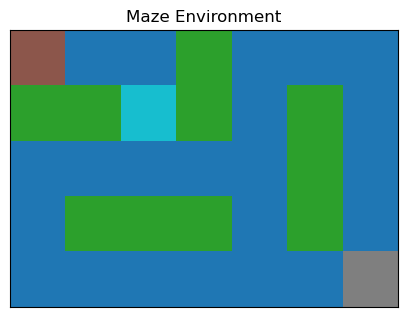

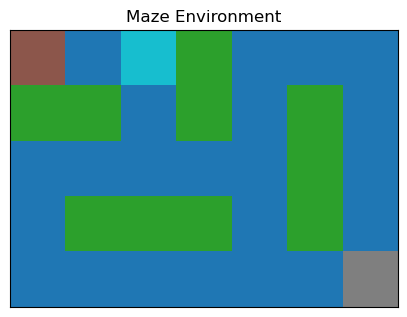

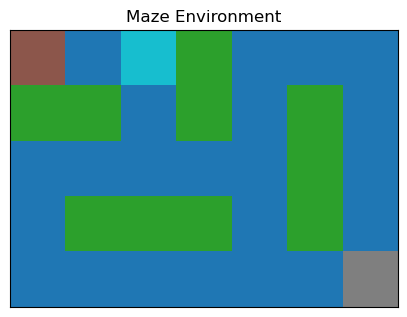

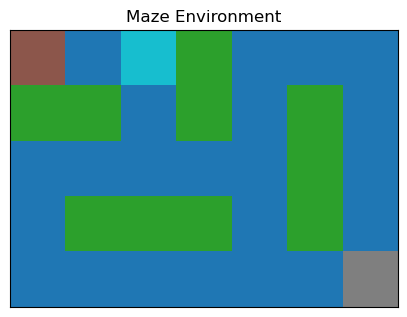

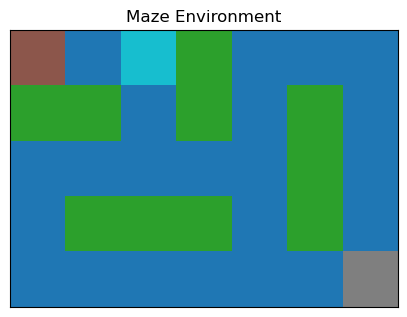

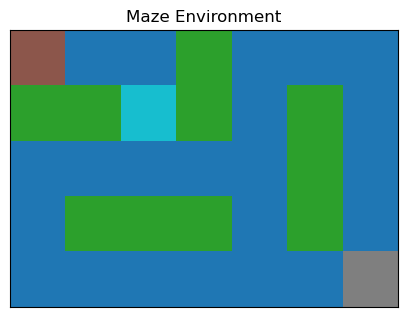

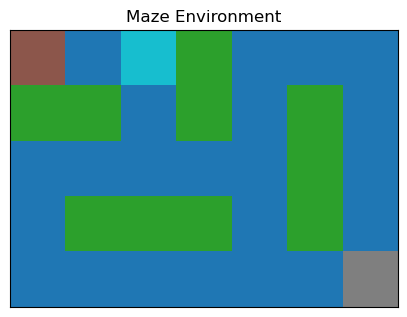

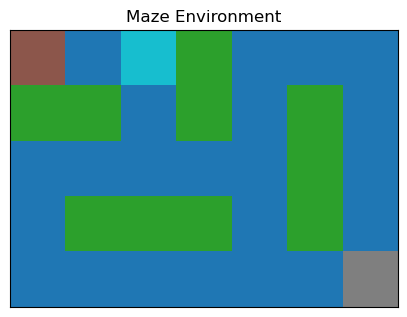

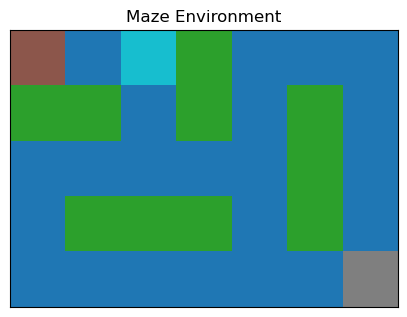

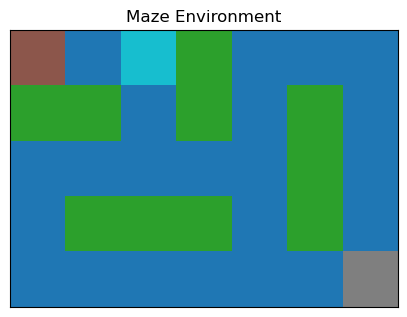

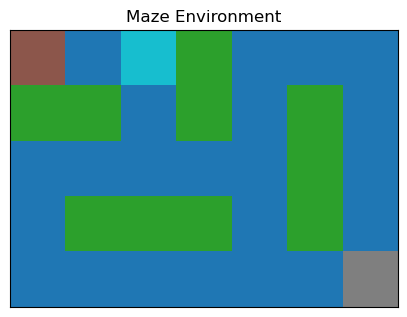

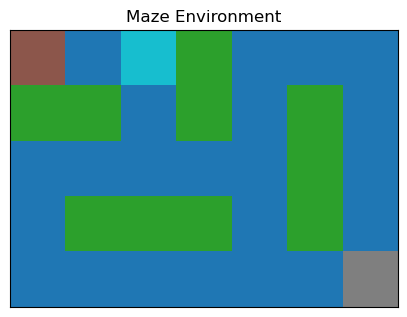

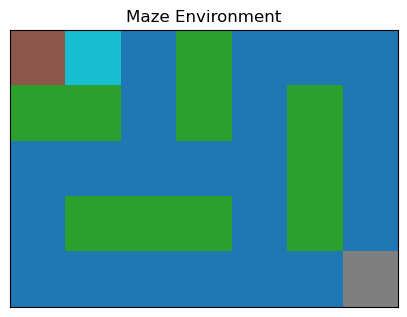

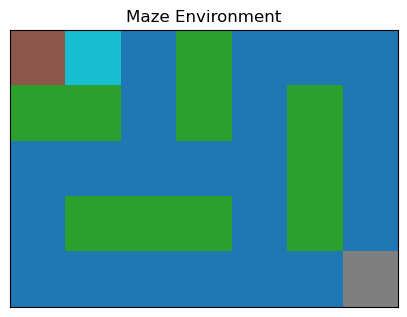

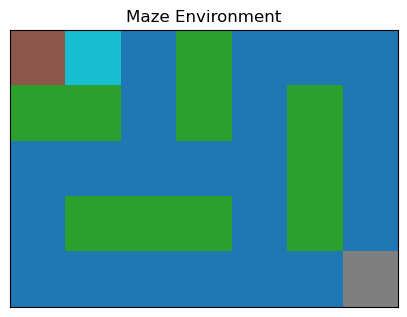

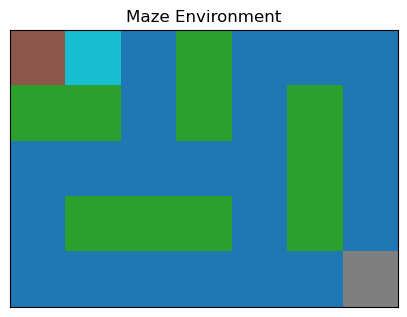

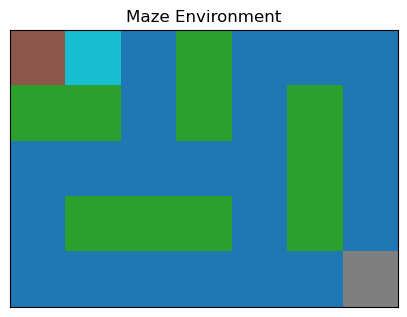

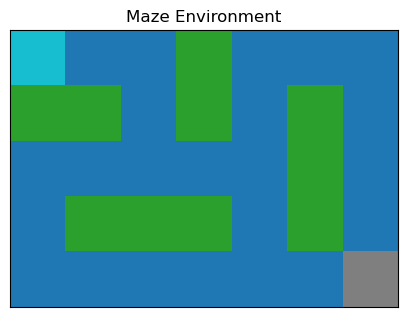

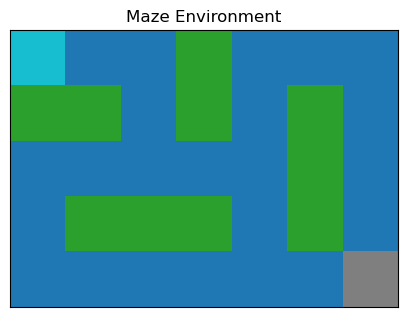

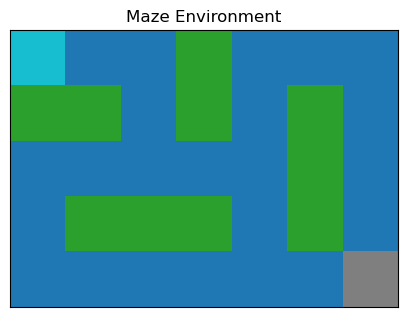

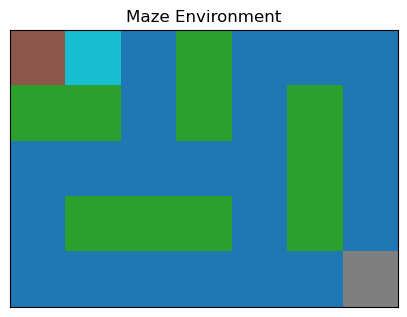

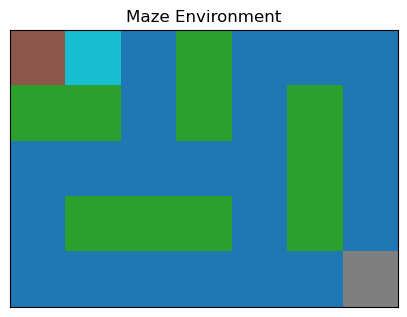

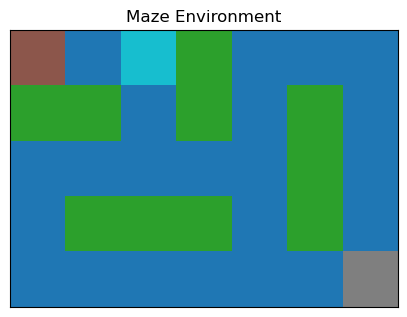

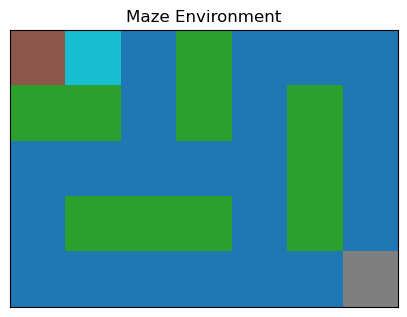

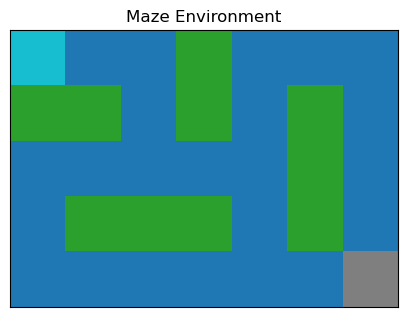

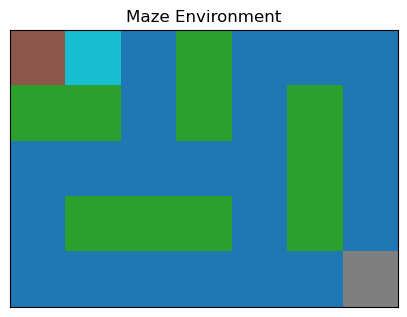

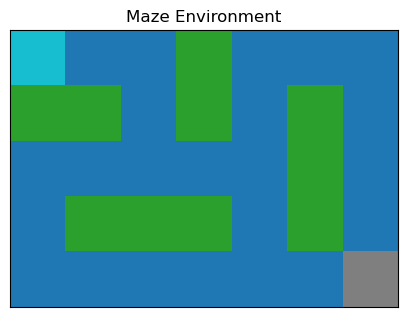

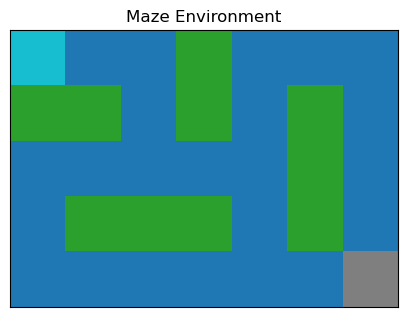

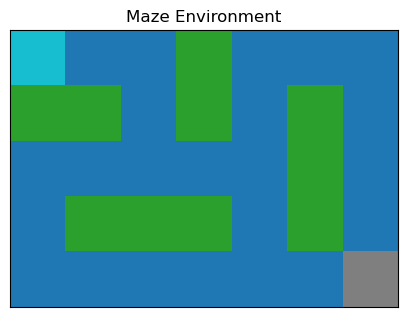

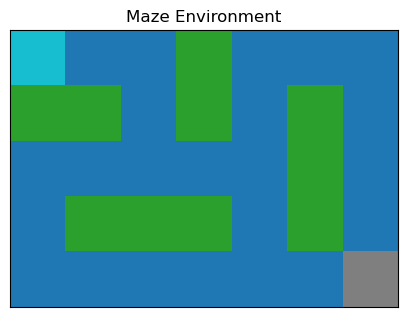

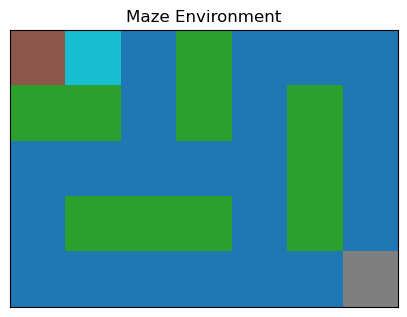

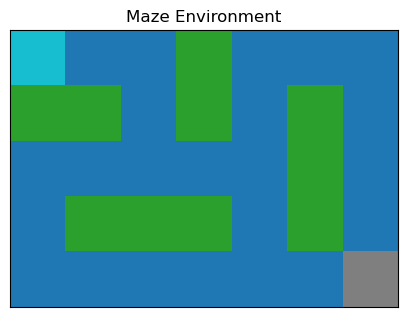

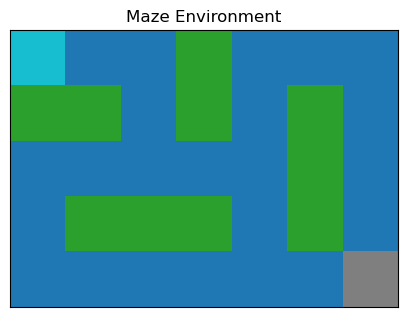

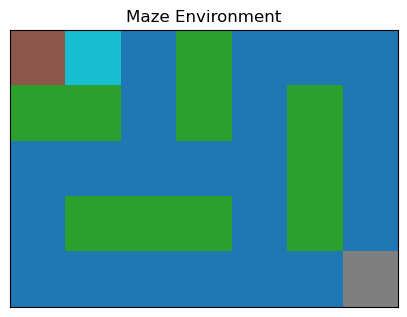

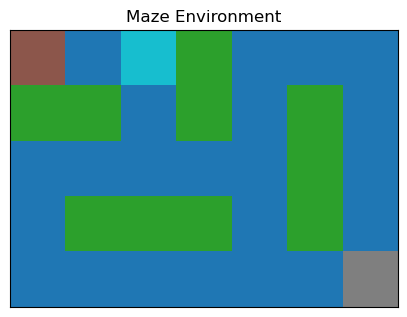

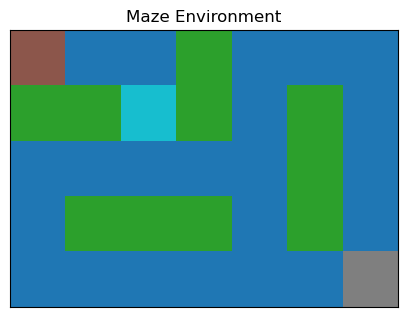

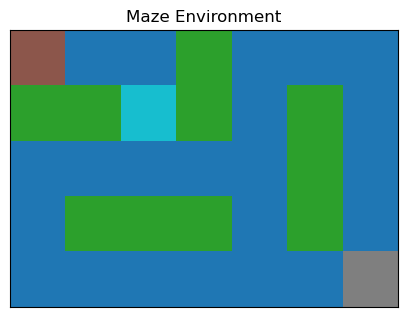

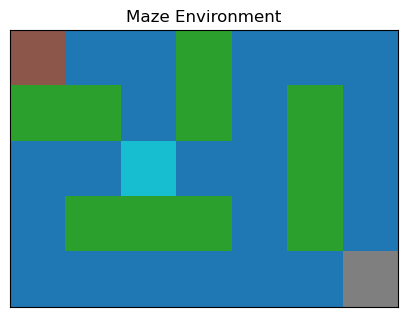

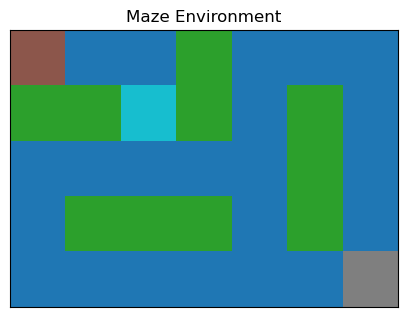

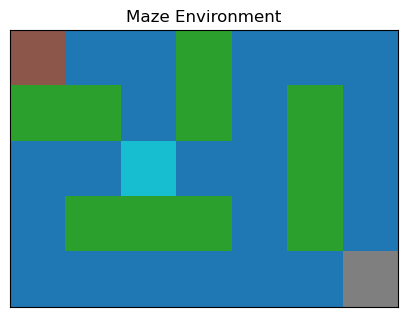

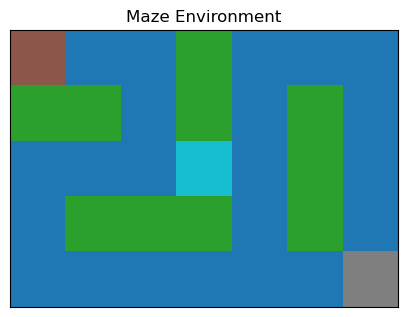

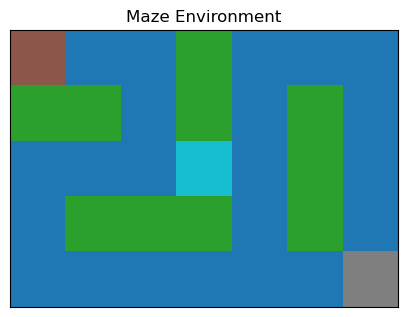

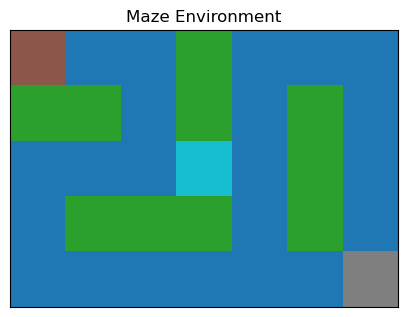

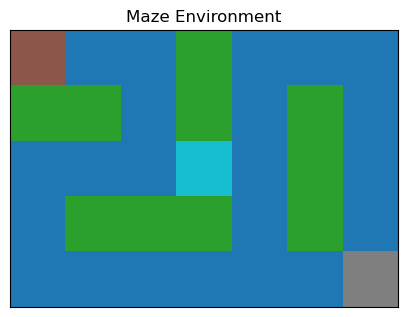

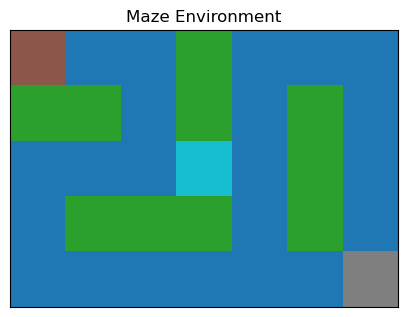

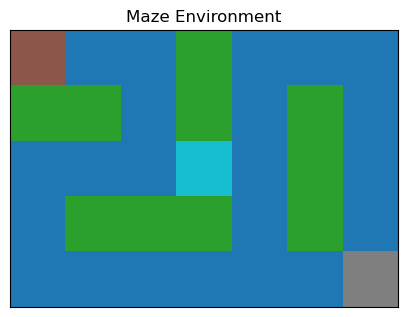

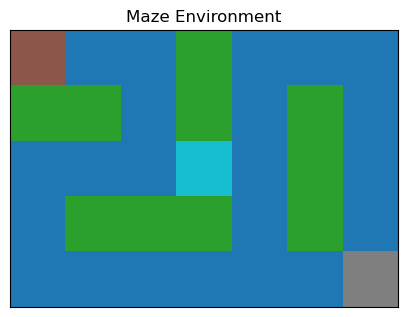

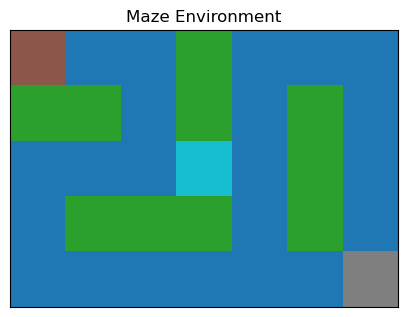

❌ Did not reach the goal. Random agent failed.


In [7]:
run_random_agent(env, max_steps=60, delay=0.25)

### Cleaner Render

In [8]:
def render(
    env,
    imagined_paths=None,
    chosen_path=None,
    title="Maze Environment"
):
    """
    imagined_paths: list of lists of (x, y) tuples
    chosen_path: list of (x, y) tuples
    """

    fig, ax = plt.subplots(figsize=(5, 5))

    # --- Draw maze background ---
    for x in range(env.height):
        for y in range(env.width):
            if env.maze[x, y] == 1:      # wall
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="black"))
            else:                        # free space
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="white"))

    # --- Draw start & goal ---
    sx, sy = env.start_pos
    gx, gy = env.goal_pos

    ax.text(sy + 0.5, sx + 0.5, "S", ha="center", va="center", fontsize=12)
    ax.text(gy + 0.5, gx + 0.5, "G", ha="center", va="center", fontsize=12)

    # --- Draw imagined trajectories (future use) ---
    if imagined_paths is not None:
        for path in imagined_paths:
            xs = [y + 0.5 for x, y in path]
            ys = [x + 0.5 for x, y in path]
            ax.plot(xs, ys, linestyle="dotted", alpha=0.4, color="blue")

    # --- Draw chosen path (future use) ---
    if chosen_path is not None:
        xs = [y + 0.5 for x, y in chosen_path]
        ys = [x + 0.5 for x, y in chosen_path]
        ax.plot(xs, ys, linewidth=2.5, color="red")

    # --- Draw agent ---
    ax.scatter(
        env.agent_pos[1] + 0.5,
        env.agent_pos[0] + 0.5,
        s=200,
        color="orange",
        zorder=5
    )

    # --- Formatting ---
    ax.set_xlim(0, env.width)
    ax.set_ylim(env.height, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.show()


- 🔵 imagined futures (dotted, translucent)

- 🔴 chosen plan

- 🟠 agent

- ⬛ walls

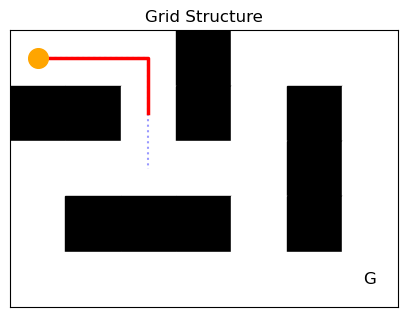

In [16]:
env.reset()
chosen_path = [(0,0), (0,1), (0,2), (1,2)]

imagined_paths = [

    [(0,0), (0,1), (0,2)],
    [(0,0), (0,1), (0,2), (1,2), (2,2)]
]

render(
    env,
    imagined_paths=globals().get("imagined_paths", None),
    chosen_path=globals().get("chosen_path", None),
    title="Grid Structure"
)


### Fake Imagination Test
#### How it will look later

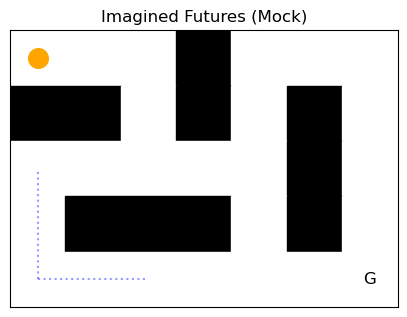

In [10]:
fake_paths = [
    [(4, 0), (4, 1), (4, 2)],
    [(4, 0), (3, 0), (2, 0)]
]

render(env, imagined_paths=fake_paths, title="Imagined Futures (Mock)")